In [88]:
import pandas as pd
import numpy as np
import seaborn as sns

In [89]:
df=pd.read_csv("C:/Users/ELCOT/Desktop/Housing Price Prediction.csv")
df

,price(in lakhs),area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,33.56,4661,2,1,2,yes,no,no,yes,no,1,no,semi-furnished
1,62.26,6806,3,1,1,yes,yes,yes,no,yes,1,yes,semi-furnished
2,65.29,8196,3,2,2,yes,no,no,no,no,0,yes,semi-furnished
3,24.31,3195,2,2,1,no,no,yes,no,no,0,no,semi-furnished
4,33.53,4222,3,1,2,yes,no,no,no,no,1,no,furnished
...,...,...,...,...,...,...,...,...,...,...,...,...,...
10995,41.61,4084,3,1,2,yes,no,no,no,no,0,no,furnished
10996,102.26,9589,4,2,2,yes,yes,yes,no,no,1,no,semi-furnished
10997,67.51,5935,3,2,4,yes,no,no,no,yes,1,no,furnished
10998,28.47,4241,2,1,2,yes,no,no,no,no,0,no,unfurnished


### BASIC UNDERSTANDING

In [3]:
df.shape

(11000, 13)

In [4]:
df.columns

Index(['price(in lakhs)', 'area', 'bedrooms', 'bathrooms', 'stories',
       'mainroad', 'guestroom', 'basement', 'hotwaterheating',
       'airconditioning', 'parking', 'prefarea', 'furnishingstatus'],
      dtype='str')

In [5]:
df.index

RangeIndex(start=0, stop=11000, step=1)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11000 entries, 0 to 10999
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   price(in lakhs)   11000 non-null  float64
 1   area              11000 non-null  int64  
 2   bedrooms          11000 non-null  int64  
 3   bathrooms         11000 non-null  int64  
 4   stories           11000 non-null  int64  
 5   mainroad          11000 non-null  str    
 6   guestroom         11000 non-null  str    
 7   basement          11000 non-null  str    
 8   hotwaterheating   11000 non-null  str    
 9   airconditioning   11000 non-null  str    
 10  parking           11000 non-null  int64  
 11  prefarea          11000 non-null  str    
 12  furnishingstatus  11000 non-null  str    
dtypes: float64(1), int64(5), str(7)
memory usage: 1.4 MB


In [7]:
df.describe()

,price(in lakhs),area,bedrooms,bathrooms,stories,parking
count,11000.000000,11000.000000,11000.000000,11000.000000,11000.000000,11000.000000
mean,47.687541,5135.506545,2.968000,1.282091,1.794545,0.681182
std,19.519782,2205.740762,0.733812,0.501445,0.859408,0.862747
min,17.500000,1441.000000,1.000000,1.000000,1.000000,0.000000
25%,33.820000,3535.750000,2.000000,1.000000,1.000000,0.000000
50%,43.940000,4602.000000,3.000000,1.000000,2.000000,0.000000
75%,57.852500,6341.250000,3.000000,2.000000,2.000000,1.000000
max,133.000000,18634.000000,6.000000,4.000000,4.000000,3.000000


In [91]:
df.rename(columns={"price(in lakhs)":"price"},inplace=True)
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,33.56,4661,2,1,2,yes,no,no,yes,no,1,no,semi-furnished
1,62.26,6806,3,1,1,yes,yes,yes,no,yes,1,yes,semi-furnished
2,65.29,8196,3,2,2,yes,no,no,no,no,0,yes,semi-furnished
3,24.31,3195,2,2,1,no,no,yes,no,no,0,no,semi-furnished
4,33.53,4222,3,1,2,yes,no,no,no,no,1,no,furnished


### HANDLING NULL

In [9]:
df.isnull().sum()

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

### HANDLING OUTLIERS

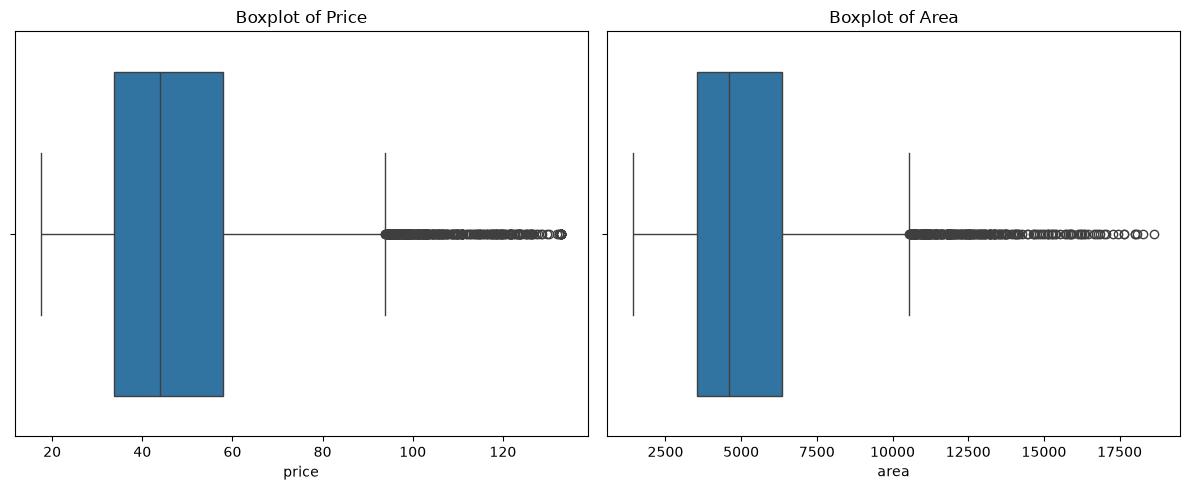

In [83]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

# Subplot 1: Price
plt.subplot(1, 2, 1)
sns.boxplot(x="price", data=df)
plt.title("Boxplot of Price")

# Subplot 2: Area
plt.subplot(1, 2, 2)
sns.boxplot(x="area", data=df)
plt.title("Boxplot of Area")

plt.tight_layout()
plt.show()

In [12]:
df["bedrooms"].value_counts()

bedrooms
3    6127
2    2732
4    1874
5     195
6      52
1      20
Name: count, dtype: int64

In [13]:
df["bathrooms"].value_counts()

bathrooms
1    8144
2    2631
3     203
4      22
Name: count, dtype: int64

In [14]:
df["stories"].value_counts()

stories
2    4815
1    4623
4     801
3     761
Name: count, dtype: int64

In [15]:
df["parking"].value_counts()

parking
0    6159
1    2436
2    2158
3     247
Name: count, dtype: int64

### FEATURE SELECTION(Correlation and Hypthesis Testing)

In [16]:
df1=df[["price","area"]]
df1.corr()

,price,area
price,1.000000,0.712663
area,0.712663,1.000000


In [17]:
#Annova
from sklearn.feature_selection import f_regression
import pandas as pd

# Assume X contains only your numerical features
# and y is your 'Weather Type' target column
X = df[
    [
        "bedrooms",
        "bathrooms",
        "stories",
        "parking",

    ]
]
y = df["price"]

f_scores, p_values = f_regression(X, y)

# Create a DataFrame to view the results clearly
feature_scores = pd.DataFrame(
    {"Feature": X.columns, "F-Score": f_scores, "P-Value": p_values}
)
print(feature_scores.sort_values(by="F-Score", ascending=False))

     Feature      F-Score        P-Value
1  bathrooms  8663.278439   0.000000e+00
0   bedrooms  3902.285759   0.000000e+00
3    parking  1473.567487  1.145698e-302
2    stories  1309.670789  4.725581e-271


In [18]:
#t_test
import pandas as pd
import scipy.stats as stats

df['mainroad'] = df['mainroad'].astype('category')

yes = df[df['mainroad'] == 'yes']['price']

no= df[df['mainroad'] == 'no']['price']

t_test_result = stats.ttest_ind(yes, no)
if t_test_result.pvalue < 0.05:
    print("There is a relationship")
else:
    print("There is no relationship")

There is a relationship


In [19]:
#t_test
import pandas as pd
import scipy.stats as stats

df['guestroom'] = df['guestroom'].astype('category')

yes = df[df['guestroom'] == 'yes']['price']

no= df[df['guestroom'] == 'no']['price']

t_test_result = stats.ttest_ind(yes, no)
if t_test_result.pvalue < 0.05:
    print("There is a relationship")
else:
    print("There is no relationship")

There is a relationship


In [20]:
#t_test
import pandas as pd
import scipy.stats as stats

df['basement'] = df['basement'].astype('category')

yes = df[df['basement'] == 'yes']['price']

no= df[df['basement'] == 'no']['price']

t_test_result = stats.ttest_ind(yes, no)
if t_test_result.pvalue < 0.05:
    print("There is a relationship")
else:
    print("There is no relationship")

There is a relationship


In [21]:
#t_test
import pandas as pd
import scipy.stats as stats

df['hotwaterheating'] = df['hotwaterheating'].astype('category')

yes = df[df['hotwaterheating'] == 'yes']['price']

no= df[df['hotwaterheating'] == 'no']['price']

t_test_result = stats.ttest_ind(yes, no)
if t_test_result.pvalue < 0.05:
    print("There is a relationship")
else:
    print("There is no relationship")

There is a relationship


In [92]:
#t_test
import pandas as pd
import scipy.stats as stats

df['airconditioning'] = df['airconditioning'].astype('category')

yes = df[df['airconditioning'] == 'yes']['price']

no= df[df['airconditioning'] == 'no']['price']

t_test_result = stats.ttest_ind(yes, no)
if t_test_result.pvalue < 0.05:
    print("There is a relationship")
else:
    print("There is no relationship")

There is a relationship


In [22]:
import pandas as pd
import scipy.stats as stats

df['furnishingstatus'] = df['furnishingstatus'].astype('category')


furnished = df[df['furnishingstatus'] == 'furnished']['price']

semi_furnished= df[df['furnishingstatus'] == 'semi-furnished']['price']
unfurnished= df[df['furnishingstatus'] == 'unfurnished']['price']

anova_result = stats.f_oneway(furnished,semi_furnished,unfurnished)


if anova_result.pvalue < 0.05:
    print("There is a  difference") # there is relationship
else:
    print("There is no significant difference")

There is a  difference


In [23]:
df.columns

Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus'],
      dtype='str')

### ENCODING

In [24]:
from sklearn.preprocessing import LabelEncoder
label = LabelEncoder()
df["mainroad"]=label.fit_transform(df["mainroad"])
df["guestroom"]=label.fit_transform(df["guestroom"])
df["basement"]=label.fit_transform(df["basement"])
df["hotwaterheating"]=label.fit_transform(df["hotwaterheating"])
df["airconditioning"]=label.fit_transform(df["airconditioning"])
df["prefarea"]=label.fit_transform(df["prefarea"])
df["furnishingstatus"]=label.fit_transform(df["furnishingstatus"])

### Splitting x and y

In [26]:
x=df.iloc[:,1:]
x

,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,4661,2,1,2,1,0,0,1,0,1,0,1
1,6806,3,1,1,1,1,1,0,1,1,1,1
2,8196,3,2,2,1,0,0,0,0,0,1,1
3,3195,2,2,1,0,0,1,0,0,0,0,1
4,4222,3,1,2,1,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
10995,4084,3,1,2,1,0,0,0,0,0,0,0
10996,9589,4,2,2,1,1,1,0,0,1,0,1
10997,5935,3,2,4,1,0,0,0,1,1,0,0
10998,4241,2,1,2,1,0,0,0,0,0,0,2


In [27]:
y=df.iloc[:,0]
y

0         33.56
1         62.26
2         65.29
3         24.31
4         33.53
          ...  
10995     41.61
10996    102.26
10997     67.51
10998     28.47
10999     23.89
Name: price, Length: 11000, dtype: float64

### TRAIN and TEST

In [28]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [29]:
x_train

,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
10735,3817,3,1,2,1,0,0,0,1,0,0,2
5937,14049,3,1,1,1,0,0,0,0,0,0,2
7642,2724,2,1,2,1,0,0,0,0,0,0,0
3328,14627,3,1,1,1,0,0,0,1,2,0,1
8681,4708,3,1,1,1,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
5734,4605,3,1,1,1,1,1,0,0,0,0,2
5191,3511,3,3,2,0,1,0,0,0,0,0,2
5390,3664,3,1,2,0,0,0,0,0,1,0,2
860,3477,2,1,1,1,0,0,1,0,0,0,1


### SCALING

In [30]:
from sklearn.preprocessing import StandardScaler
obj=StandardScaler()
x_train_scaled=obj.fit_transform(x_train)
x_test_scaled=obj.transform(x_test)

### Model Building, Training Testing Accuracy, MAE, MSE, RMSE, Hyperparameter Tuning

In [31]:
from sklearn.linear_model import LinearRegression
linear=LinearRegression()
linear.fit(x_train_scaled,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](12,)","[10.9 , 4.74, 8.68,..., 0.5 , 1.2 ,-0.25]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,47.56
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,12
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(12)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](12,)","[145.99,118.1 ,106.31,..., 72.91, 71.32, 60.68]"


In [32]:
#training accuracy
y_tr=linear.predict(x_train_scaled)
from sklearn.metrics import r2_score
training_linear=r2_score(y_train,y_tr)
training_linear

0.8690022586663686

In [33]:
#testing accuracy
y_te=linear.predict(x_test_scaled)
from sklearn.metrics import r2_score
testing_linear=r2_score(y_test,y_te)
testing_linear

0.8683257501255013

In [34]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("MAE:", mean_absolute_error(y_test, y_te))
print("MSE:", mean_squared_error(y_test, y_te))
print("RMSE", np.sqrt(mean_squared_error(y_test, y_te)))

MAE: 5.670570324950252
MSE: 50.936203635165484
RMSE 7.136960391873104


In [58]:
from sklearn.neighbors import KNeighborsRegressor
knn=KNeighborsRegressor(metric = 'euclidean', n_neighbors = 11)
knn.fit(x_train_scaled,y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",11
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'euclidean'
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


In [59]:
#training accuracy
y_tr1=knn.predict(x_train_scaled)
from sklearn.metrics import r2_score
training_knn=r2_score(y_train,y_tr1)
training_knn

0.910247674898838

In [60]:
#testing accuracy
y_te1=knn.predict(x_test_scaled)
from sklearn.metrics import r2_score
testing_knn=r2_score(y_test,y_te1)
testing_knn

0.8958736522958584

In [43]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("MAE:", mean_absolute_error(y_test, y_te1))
print("MSE:", mean_squared_error(y_test, y_te1))
print("RMSE", np.sqrt(mean_squared_error(y_test, y_te1)))

MAE: 5.15478
MSE: 42.29870901454546
RMSE 6.50374576798213


In [56]:
from sklearn.model_selection import GridSearchCV

KNN_PARAMETER = {'n_neighbors': [3, 5, 7, 11],'metric': ['euclidean', 'manhattan'],}


grid_search = GridSearchCV(KNeighborsRegressor(), KNN_PARAMETER, cv=5)


grid_search.fit(x_train_scaled, y_train)


print(grid_search.best_params_)
print(grid_search.best_score_)

{'metric': 'euclidean', 'n_neighbors': 11}
0.888142171632793


In [ ]:
#Without Hyperparameter Tuning
#Training - 0.9237066464678042
#Testing - 0.8906543797405275
#MAE - 5.15478

In [77]:
from sklearn.svm import SVR
svm=SVR()
svm.fit(x_train_scaled,y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


In [78]:
#Training Accuracy
y_tr2=svm.predict(x_train_scaled)
training_svm=r2_score(y_train,y_tr2)
training_svm

0.8815942288832717

In [79]:
#Testing Accuracy
y_te2=svm.predict(x_test_scaled)
testing_svm=r2_score(y_test,y_te2)
testing_svm

0.8730393525971853

In [80]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("MAE:", mean_absolute_error(y_test, y_te2))
print("MSE:", mean_squared_error(y_test, y_te2))
print("RMSE", np.sqrt(mean_squared_error(y_test, y_te2)))

MAE: 5.224322595199612
MSE: 49.11281739539762
RMSE 7.0080537523193716


In [63]:
from sklearn.tree import DecisionTreeRegressor
decision=DecisionTreeRegressor(max_depth= 10, min_samples_leaf= 10, min_samples_split= 2)
decision.fit(x_train,y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",10
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes

In [64]:
#Training Accuracy
y_tr3=decision.predict(x_train)
from sklearn.metrics import r2_score
training_decision=r2_score(y_tr3,y_train)
training_decision

0.9014704040632769

In [65]:
#Testing Accuracy
y_te3=decision.predict(x_test)
from sklearn.metrics import r2_score
testing_decision=r2_score(y_test,y_te3)
testing_decision

0.890219256914168

In [66]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("MAE:", mean_absolute_error(y_test, y_te3))
print("MSE:", mean_squared_error(y_test, y_te3))
print("RMSE", np.sqrt(mean_squared_error(y_test, y_te3)))

MAE: 5.1814173378260735
MSE: 42.46702973716872
RMSE 6.516673210862175


In [61]:
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.tree import DecisionTreeRegressor

# 1. Regression-compatible parameter grid
param_grid = {
    "max_depth": [5, 6, 8, 10, 14, 20],
    "min_samples_split": [2, 5, 7, 10, 15,7],
    "min_samples_leaf": [1, 2, 4, 6, 8, 10],
}

# 2. Set up cross-validation with shuffle=True
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# 3. Initialize DecisionTreeRegressor with a random_state
dt = DecisionTreeRegressor(random_state=42)

# 4. GridSearchCV with R2 scoring
grid_search = GridSearchCV(
    estimator=dt, param_grid=param_grid, cv=5, scoring='r2', n_jobs=-1
)

# 5. Fit
grid_search.fit(x_train, y_train)

# 6. Best parameters and evaluation
print('Best Parameters:', grid_search.best_params_)
print(f'Best CV R² Score: {grid_search.best_score_:.4f}')


Best Parameters: {'max_depth': 10, 'min_samples_leaf': 10, 'min_samples_split': 2}
Best CV R² Score: 0.8836


In [ ]:
#Without Hyperparameter Tuning
#Training - 0.9989377288105618
#Testing - 0.8111980540047572
#MAE - 6.761175000000001

In [73]:
from sklearn.ensemble import RandomForestRegressor
rf=RandomForestRegressor(max_depth=10, min_samples_leaf= 4, min_samples_split= 10, n_estimators = 200)
rf.fit(x_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",4
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the numbe

In [74]:
y_tr4=rf.predict(x_train)
from sklearn.metrics import r2_score
training_rf=r2_score(y_train,y_tr4)
training_rf

0.9207519216283002

In [75]:
#Testing Accuracy
y_te3=rf.predict(x_test)
from sklearn.metrics import r2_score
testing_rf=r2_score(y_test,y_te3)
testing_rf

0.9017131220030895

In [76]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

print("MAE:", mean_absolute_error(y_test, y_te3))
print("MSE:", mean_squared_error(y_test, y_te3))
print("RMSE", np.sqrt(mean_squared_error(y_test, y_te3)))

MAE: 4.892360993737079
MSE: 38.020800855801035
RMSE 6.166100944340843


In [71]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, KFold

# 1. Regression-compatible parameter grid
param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [5, 8, 10, 14, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4, 6],
}

# 2. Set up cross-validation with shuffle=True
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# 3. Initialize RandomForestRegressor with a random_state
rf = RandomForestRegressor(random_state=42)

# 4. GridSearchCV with R2 scoring
grid_search = GridSearchCV(
    estimator=rf, param_grid=param_grid, cv=kf, scoring="r2", n_jobs=-1
)

# 5. Fit
grid_search.fit(x_train, y_train)

# 6. Best parameters and evaluation
print("Best Parameters:", grid_search.best_params_)
print(f"Best CV R² Score: {grid_search.best_score_:.4f}")

Best Parameters: {'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 200}
Best CV R² Score: 0.8965


In [ ]:
#Without Hyperparameter Tuning
#Training - 0.9823364997722105
#Testing - 0.8836365705047425
#MAE - 5.266024177380953

In [84]:
import pandas as pd

comparison_data = {
    "Model": [
        "Linear Regression",
        "KNN",
        "SVR",
        "Decision Tree",
        "Random Forest",
    ],
    "Train Score": [0.87, 0.91, 0.88, 0.90, 0.92],
    "Test Score": [0.87, 0.89, 0.87, 0.89, 0.90],
    "MAE": [5.67, 5.15, 5.22, 5.18, 4.89],
    "RMSE": [7.14, 6.50, 7.01, 6.52, 6.17],
    "Gap": [0.00, 0.02, 0.01, 0.01, 0.02],
    "Generalization": [
        "Well Generalized",
        "Well Generalized",
        "Well Generalized",
        "Well Generalized",
        "Best Generalized ",
    ],
    "Bias-Variance": [
        "Balanced",
        "Balanced",
        "Balanced",
        "Balanced",
        "Balanced",
    ],
    "Best Generalized Model": [
        "No",
        "No",
        "No",
        "No",
        "YES ",
    ],
}

comparison = pd.DataFrame(comparison_data)
comparison

,Model,Train Score,Test Score,MAE,RMSE,Gap,Generalization,Bias-Variance,Best Generalized Model
0,Linear Regression,0.87,0.87,5.67,7.14,0.00,Well Generalized,Balanced,No
1,KNN,0.91,0.89,5.15,6.50,0.02,Well Generalized,Balanced,No
2,SVR,0.88,0.87,5.22,7.01,0.01,Well Generalized,Balanced,No
3,Decision Tree,0.90,0.89,5.18,6.52,0.01,Well Generalized,Balanced,No
4,Random Forest,0.92,0.90,4.89,6.17,0.02,Best Generalized,Balanced,YES
